In [ ]:
# DATASET : bebe.csv
from google.colab import files
uploaded = files.upload()

Saving bebe.csv to bebe.csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

Data = pd.read_csv('bebe.csv')
df = pd.DataFrame(data = Data)
print(df.describe())

mydf = df.drop('X', axis=1)
print(mydf.head())

                 X          bwt    gestation       parity          age  \
count  1174.000000  1174.000000  1174.000000  1174.000000  1174.000000   
mean    587.500000  3386.702747   279.101363     0.262351    27.228279   
std     339.048915   519.608671    16.010305     0.440100     5.817839   
min       1.000000  1559.222500   148.000000     0.000000    15.000000   
25%     294.250000  3061.746000   272.000000     0.000000    23.000000   
50%     587.500000  3401.940000   280.000000     0.000000    26.000000   
75%     880.750000  3713.784500   288.000000     1.000000    31.000000   
max    1174.000000  4989.512000   353.000000     1.000000    45.000000   

            height       weight        smoke  
count  1174.000000  1174.000000  1174.000000  
mean    162.685486    58.276913     0.390971  
std       6.416298     9.404905     0.488176  
min     134.620000    39.462504     0.000000  
25%     157.480000    51.822886     0.000000  
50%     162.560000    56.699000     0.000000  
75% 

**Commentez les valeurs médianes pour les variables quantitatives et les modalités les plus représentées pour les variables qualitatives.**

On a des valeurs plutot

 **Y-a-t-il des valeurs manquantes ? Pourquoi cela peut-il être un problème pour
l'entraînement du modèle ?**

Non, il n'y a pas de valeur manquantes, mais si il y en avait cela aurait été génant pour le modèle.

In [ ]:
import pandas as pd
mydf.isna().sum()

,0
bwt,0
gestation,0
parity,0
age,0
height,0
weight,0
smoke,0


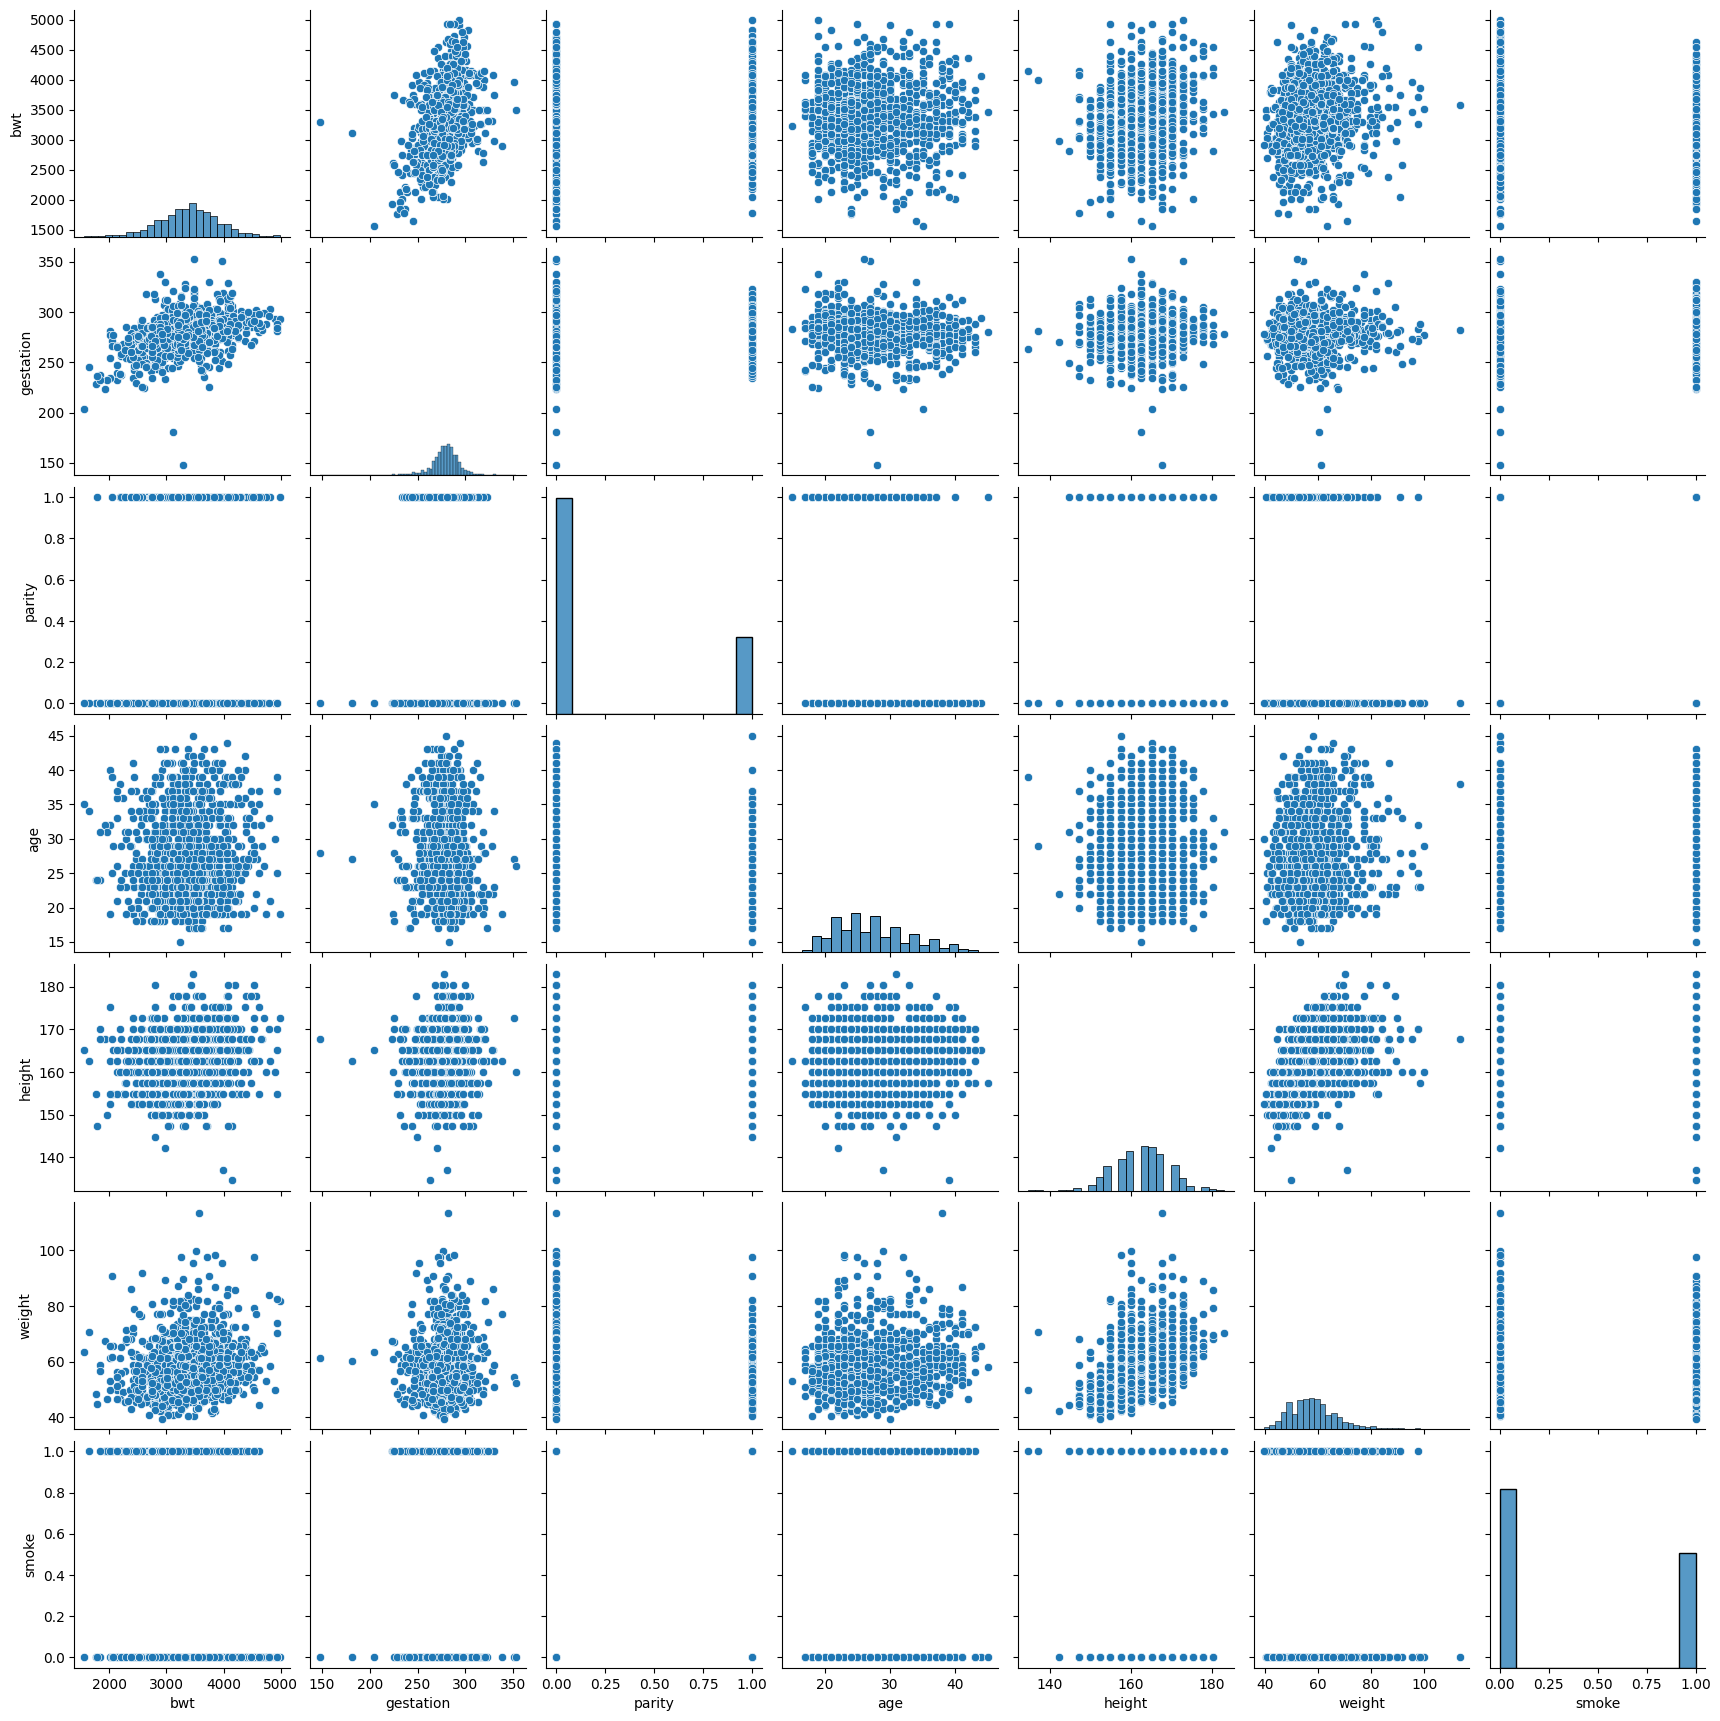

In [ ]:
#create pairs plot for all numeric variables
sns.pairplot(mydf)

**Identifiez les forte corrélations entre les variables.**

Il n'y a pas de forte corélation, les points sont trop dispercés pour pouvoir faire une droite.

**Identifiez les faibles corrélations entre les variables.**

Il y a quelques faibles corrélation mais qui restent très dispercésrr

**Y-a-t-il plus de mère fumeuses ou non fumeuse ?**

Non il y a plus de mères non fumeuses que fumeuses

**Pour construire un bon modèle, nous devons d’abord diviser notre ensemble
de données en un ensemble d’entraînement et un ensemble de test. Construire
les dataframe X_test, X_test, Y_train, Y_test à l’aide de la fonction train_test_split de sklearn.model_selection en utilisant 70% de l’échantillon pour des données de train et les 30% restants pour les données de test (on fixera la graine à 42. Y_train, Y_test seront associés à la variable à prédire et X_test, X_test aux variables explicatives.**



In [ ]:
mydf.loc[:, mydf.columns != "bwt"].head()

,gestation,parity,age,height,weight,smoke
0,284,0,27,157.48,45.359200,0
1,282,0,33,162.56,61.234920,0
2,279,0,28,162.56,52.163080,1
3,282,0,23,170.18,56.699000,1
4,286,0,25,157.48,42.184056,0


In [ ]:
from sklearn.model_selection import train_test_split


X_train, X_test, Y_train, Y_test = train_test_split(mydf.loc[:, mydf.columns != "bwt"], mydf.loc[:, mydf.columns == "bwt"],test_size=0.3,random_state=42)

In [ ]:
X_train.head()

,gestation,parity,age,height,weight,smoke
985,296,1,24,165.10,59.874144,0
997,266,0,23,152.40,54.431040,1
316,271,1,30,170.18,65.317248,1
596,292,1,21,172.72,58.966960,1
830,276,1,23,165.10,56.699000,1


In [ ]:
Y_train.head()

,bwt
985,3458.6390
997,2579.8045
316,3288.5420
596,3600.3865
830,2438.0570


In [ ]:
?DecisionTreeRegressor

In [ ]:

from sklearn.tree import DecisionTreeRegressor


# Fit regression model
regr_1 = DecisionTreeRegressor(max_depth=2)

regr_1.fit(X_train, Y_train)

regr_2 = DecisionTreeRegressor(max_depth=3)
regr_2.fit(X_train, Y_train)

regr_3 = DecisionTreeRegressor(max_depth=10)
regr_3.fit(X_train, Y_train)



DecisionTreeRegressor(max_depth=10)

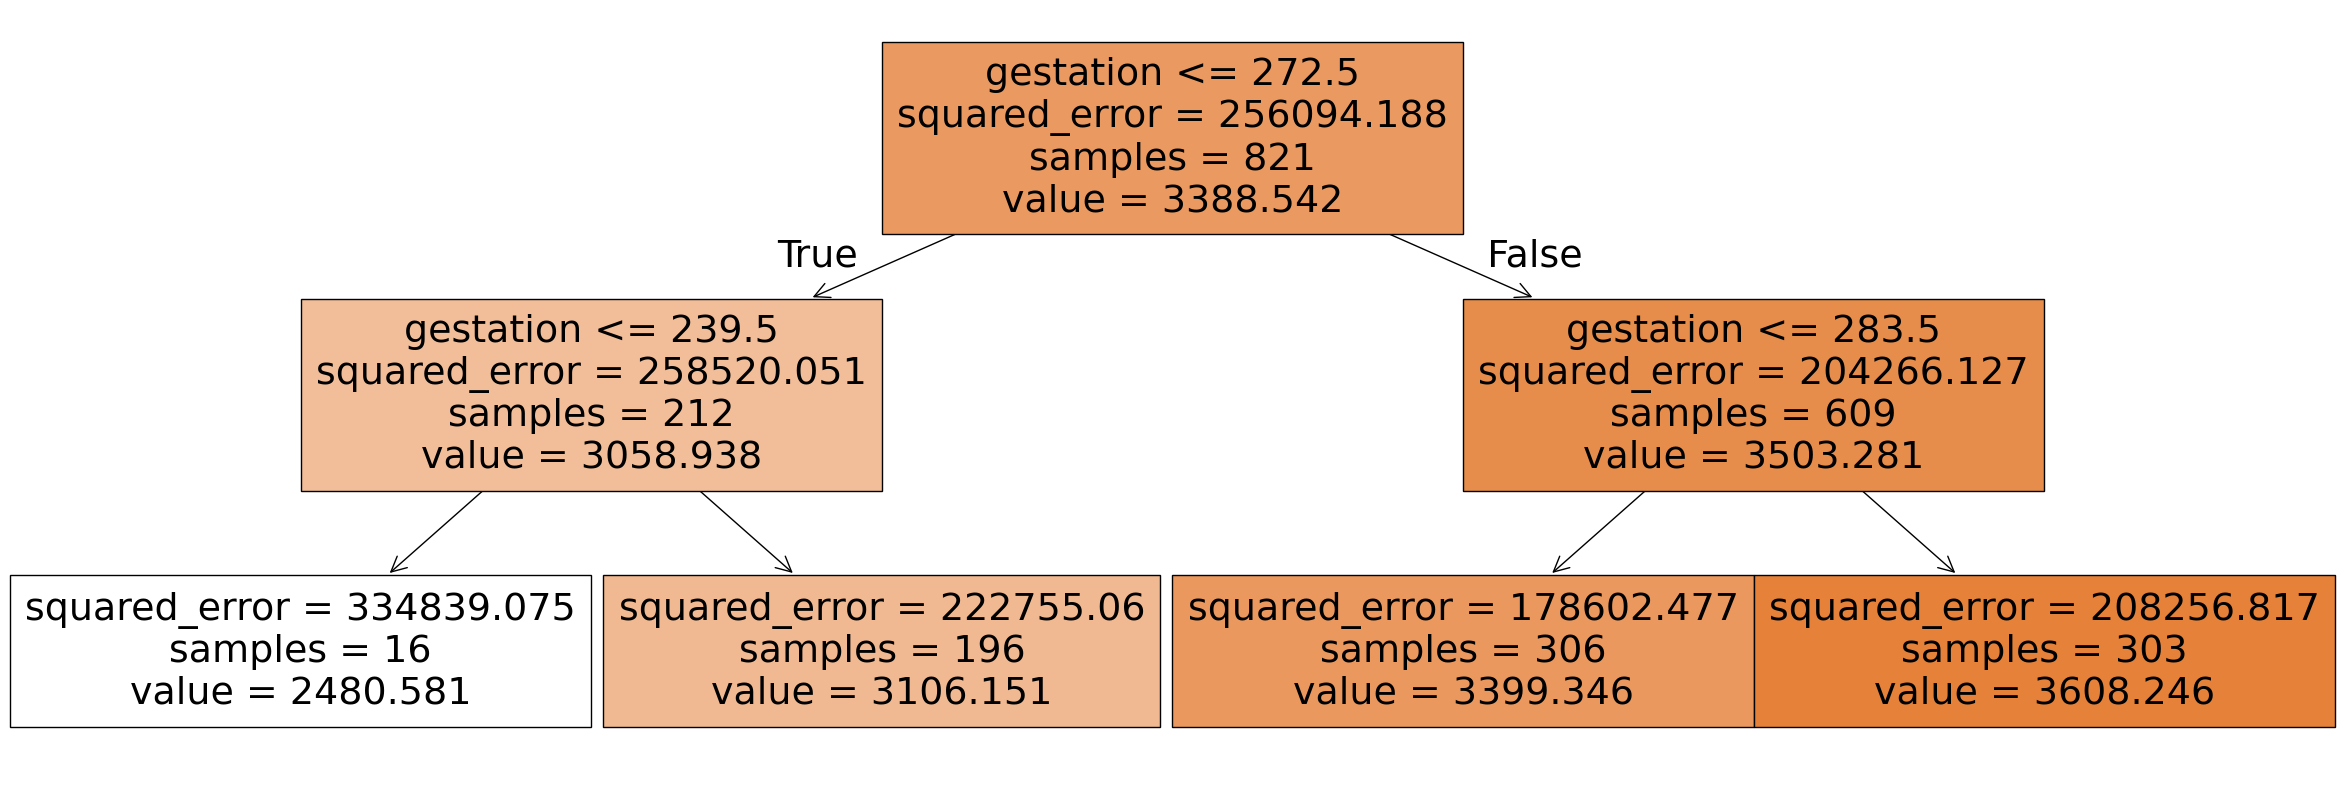

In [ ]:
import matplotlib
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
dt_feature_names =  list(X_train.columns)

# Plot the decision tree
plt.figure(figsize=(30, 10))
plot_tree(regr_1, filled=True, feature_names=dt_feature_names)
plt.show()

In [ ]:
# Predict

y_1 = regr_1.predict(X_test)
y_2 = regr_2.predict(X_test)


y_3 = regr_3.predict(X_test)
X_test_temp = X_test.loc[:, X_test.columns == "gestation"]



In [ ]:
from sklearn.metrics import r2_score

R-squared: 0.2216432399460484
MSE:  234696.44258601364
RMSE:  484.4547890010105


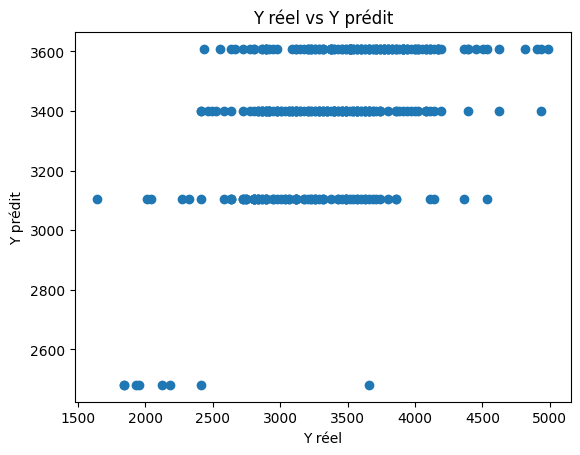

In [ ]:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(Y_test, y_1)
score =  r2_score(Y_test, y_1)

print("R-squared:", score)
print("MSE: ", mse)
print("RMSE: ", mse**(1/2.0))
plt.scatter(Y_test, y_1, )
plt.title("Y réel vs Y prédit")
plt.xlabel("Y réel")
plt.ylabel("Y prédit")
plt.show()

**Commentez l’arbre obtenu (description des groupes). Quelle est/sont les va-
riables de split les plus discriminantes ?**



**Donnez la formule pour calculer manuellement le R2 et la M SE Retrouvez
les résultats obtenus avec sklearn.**



**Commentez le R2 obtenu. Comparez le avec le R2 issue des données d’entraî-
nement. Est-on en underfit ou overfit ?**



**Commentez le graphe 1.3. Commnent se comporte le modèle.**

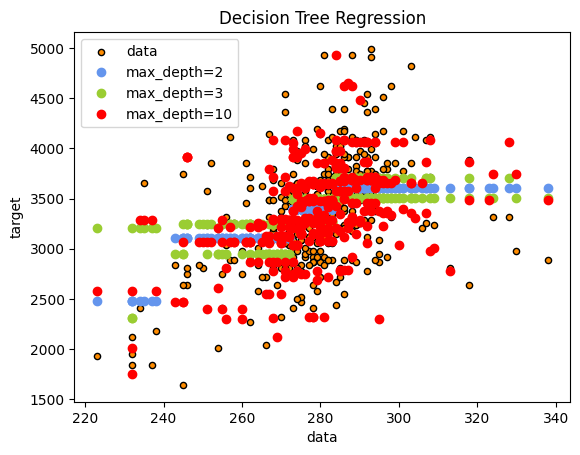

In [ ]:
# Plot the results
plt.figure()
plt.scatter(X_test_temp, Y_test, s=20, edgecolor="black", c="darkorange", label="data")
plt.plot(X_test_temp, y_1,'o', color="cornflowerblue", label="max_depth=2")
plt.plot(X_test_temp, y_2, 'o',color="yellowgreen", label="max_depth=3")
plt.plot(X_test_temp, y_3, 'o',color="red", label="max_depth=10")
plt.xlabel("data")
plt.ylabel("target")
plt.title("Decision Tree Regression")
plt.legend()
plt.show()

In [ ]:
# Step 3: Calculating the score of the predictive power on the training and testing dataset.
from sklearn.metrics import r2_score

print('r2 score for regr1 model is', r2_score( Y_train, regr_1.predict(X_train)),'for the train and ',r2_score( Y_test, regr_1.predict(X_test)),'for the test')


print('r2 score for regr1 model is', r2_score( Y_train, regr_3.predict(X_train)),'for the train and ',r2_score( Y_test, regr_3.predict(X_test)),'for the test')



r2 score for regr1 model is 0.20680641973201364 for the train and  0.2216432399460484 for the test
r2 score for regr1 model is 0.7487003985392255 for the train and  -0.10864424521608118 for the test


In [ ]:
print('r2 score for regr2 model is', r2_score( Y_train, regr_2.predict(X_train)),'for the train and ',r2_score( Y_test, regr_2.predict(X_test)),'for the test')


r2 score for regr2 model is 0.26795330871078726 for the train and  0.20871515150482645 for the test


In [ ]:
regr_3 = DecisionTreeRegressor(criterion='squared_error',
    splitter='best',
    max_depth=10,
    min_samples_split=2,
    min_samples_leaf=5,
    min_weight_fraction_leaf=0.05,
    max_features=None,
    random_state=42,
    max_leaf_nodes=None,
    min_impurity_decrease=0.0,
    ccp_alpha=0.03)

regr_3.fit(X_train, Y_train)
print('r2 score for regr3 model is', r2_score( Y_train, regr_3.predict(X_train)),'for the train and ',r2_score( Y_test, regr_3.predict(X_test)),'for the test')


r2 score for regr3 model is 0.28099218172611684 for the train and  0.24090689173162871 for the test


# Exo 2

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
uploaded = files.upload()
myData = pd.read_csv('titanic.csv')
print(myData.head())

Saving titanic.csv to titanic.csv
   id      class     age  sex survived
0   1  1st class  adults  man      yes
1   2  1st class  adults  man      yes
2   3  1st class  adults  man      yes
3   4  1st class  adults  man      yes
4   5  1st class  adults  man      yes


In [ ]:
myData.astype('object').describe()

,id,class,age,sex,survived
count,1316,1316,1316,1316,1316
unique,1316,3,2,2,2
top,1316,3rd class,adults,man,no
freq,1,706,1207,869,817


In [ ]:
myData.drop('id', inplace=True, axis=1)
myData.head()

,class,age,sex,survived
0,1st class,adults,man,yes
1,1st class,adults,man,yes
2,1st class,adults,man,yes
3,1st class,adults,man,yes
4,1st class,adults,man,yes


In [ ]:
myData_bin = pd.get_dummies(myData, columns=['class','age','sex'])

X, y = myData_bin.loc[:, myData_bin.columns != 'survived'] , myData_bin['survived']
print(X.head())

   class_1st class  class_2nd class  class_3rd class  age_adults  age_child  \
0             True            False            False        True      False   
1             True            False            False        True      False   
2             True            False            False        True      False   
3             True            False            False        True      False   
4             True            False            False        True      False   

   sex_man  sex_women  
0     True      False  
1     True      False  
2     True      False  
3     True      False  
4     True      False  


In [ ]:
X_train, X_test, y_train, y_test =  train_test_split(X, y, train_size=0.7, random_state=0)

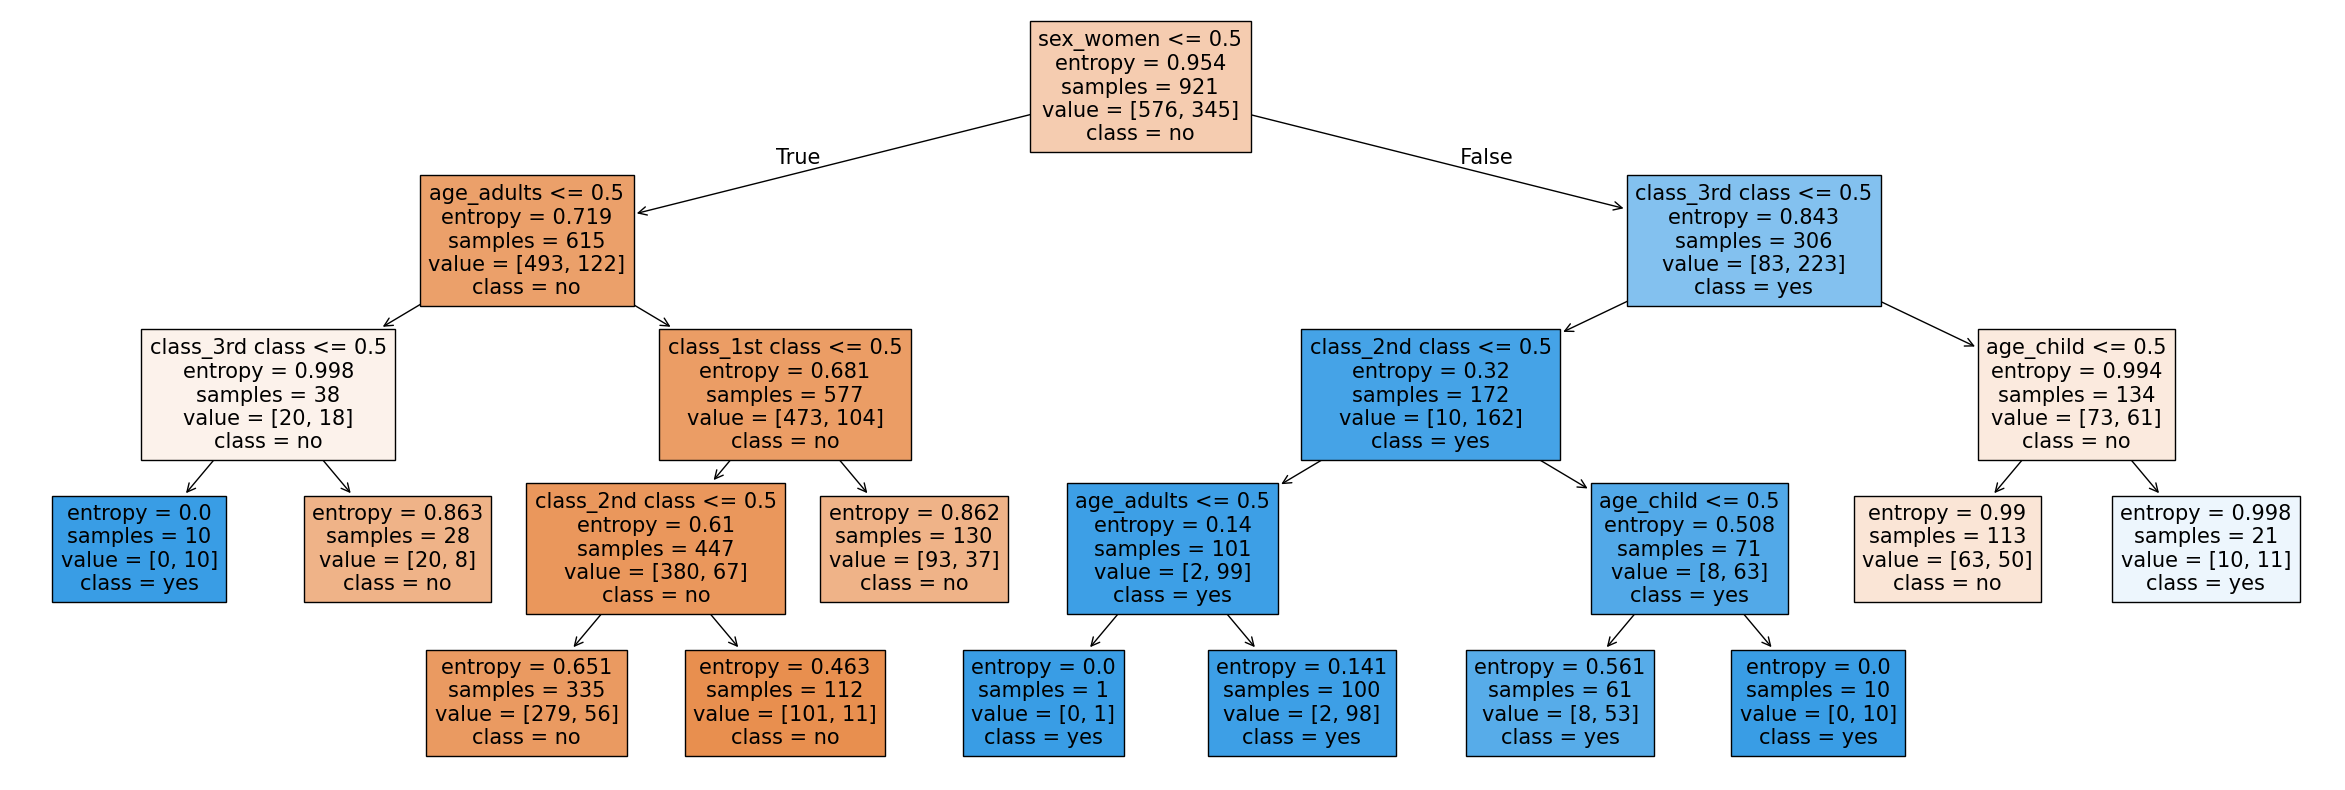

In [ ]:
from sklearn import tree

clf = tree.DecisionTreeClassifier(criterion='entropy')
clf.fit(X_train, y_train)
cn=[ 'no','yes']
dt_feature_names =  list(X.columns)

# plot tree
plt.figure(figsize=(30,10))  # set plot size (denoted in inches)
plot_tree_cor  = tree.plot_tree(clf,class_names=cn, filled=True, feature_names=dt_feature_names, )
plt.show()



In [ ]:
?tree.DecisionTreeClassifier

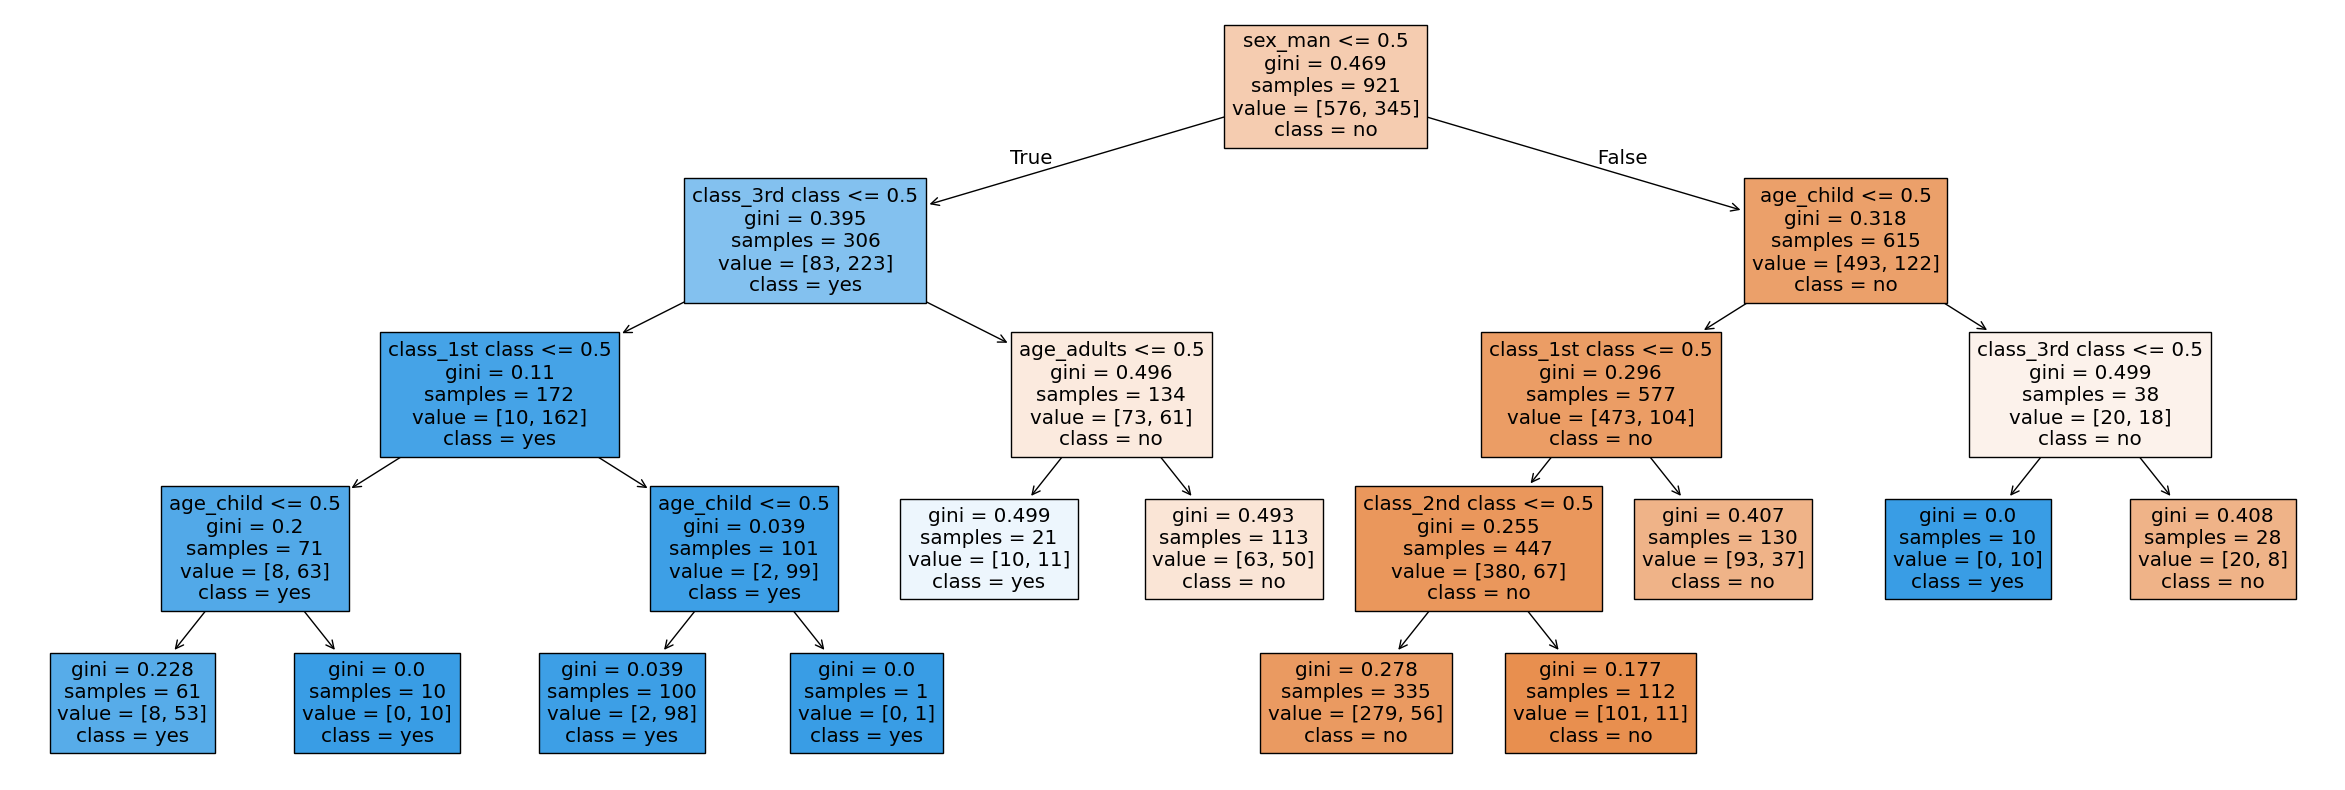

In [ ]:
from sklearn import tree

clf2 = tree.DecisionTreeClassifier(criterion='gini')
clf2.fit(X_train, y_train)
cn=[ 'no','yes']
dt_feature_names =  list(X.columns)

# plot tree
plt.figure(figsize=(30,10))  # set plot size (denoted in inches)
plot_tree_cor  = tree.plot_tree(clf2,class_names=cn, filled=True, feature_names=dt_feature_names, )
plt.show()


In [ ]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, clf.predict(X_test))
print('Confusion matrix\n\n', cm)

Confusion matrix

 [[227  14]
 [ 73  81]]


In [ ]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, clf2.predict(X_test))
print('Confusion matrix\n\n', cm)

Confusion matrix

 [[227  14]
 [ 73  81]]


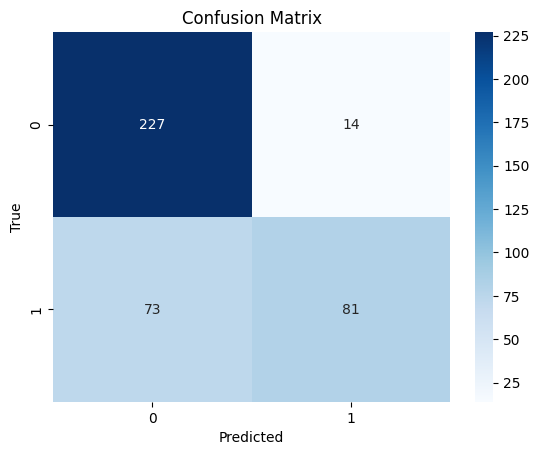

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Plot the confusion matrix using seaborn
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()


In [ ]:
# importing the module
from sklearn.metrics import  hinge_loss, log_loss

# printing the loss functions
log_loss( pd.Series(y_test).map(dict(yes=1, no=0)),  pd.Series(clf.predict(X_test)).map(dict(yes=1, no=0)))


7.938728721147322

In [ ]:
hinge_loss( pd.Series(y_test).map(dict(yes=1, no=0)),  pd.Series(clf.predict(X_test)).map(dict(yes=1, no=0)))


np.float64(0.830379746835443)